In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
from pathlib import Path

sys.path.append(str(Path().resolve().parent / "src"))

from results import ModelResults, ModelComparison, build_dataset

In [5]:
dataset = build_dataset()
ddpm_results = ModelResults('024-baseline-1', 'ddpm-1000', epoch=99, dataset_split='test', dataset=dataset)
mednext_m_results = ModelResults('040-mednext', 'unet', epoch=99, dataset_split='test', dataset=dataset)
c3d_2d_results = ModelResults('041-c3d-2d', 'unet', epoch=99, dataset_split='test', dataset=dataset)
mednext_s_results = ModelResults('042-mednext-small', 'unet', epoch=99, dataset_split='test', dataset=dataset)
mednext_b_results = ModelResults('043-mednext-base', 'unet', epoch=99, dataset_split='test', dataset=dataset)
mednext_l_results = ModelResults('044-mednext-large', 'unet', epoch=99, dataset_split='test', dataset=dataset)

comparison = ModelComparison(
    [
      ddpm_results,
      mednext_s_results,
      # mednext_b_results,
      mednext_m_results,
      mednext_l_results,
      c3d_2d_results
    ],
    [
      'DDPM',
      'MedNeXt Small',
      # 'MedNeXt Base',
      'MedNeXt Medium',
      'MedNeXt Large',
      'C3D-2D'
]
)

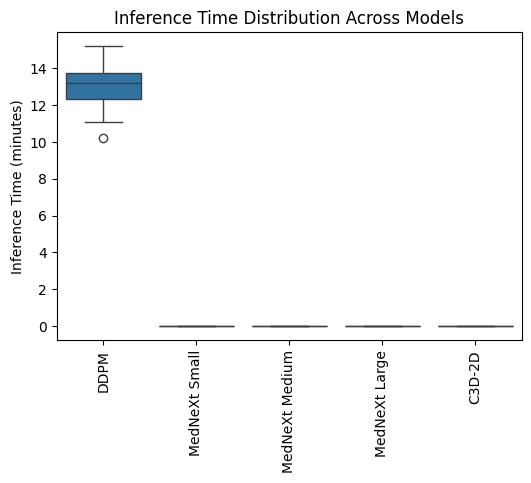

In [4]:
ax = comparison.plot_inference_times()

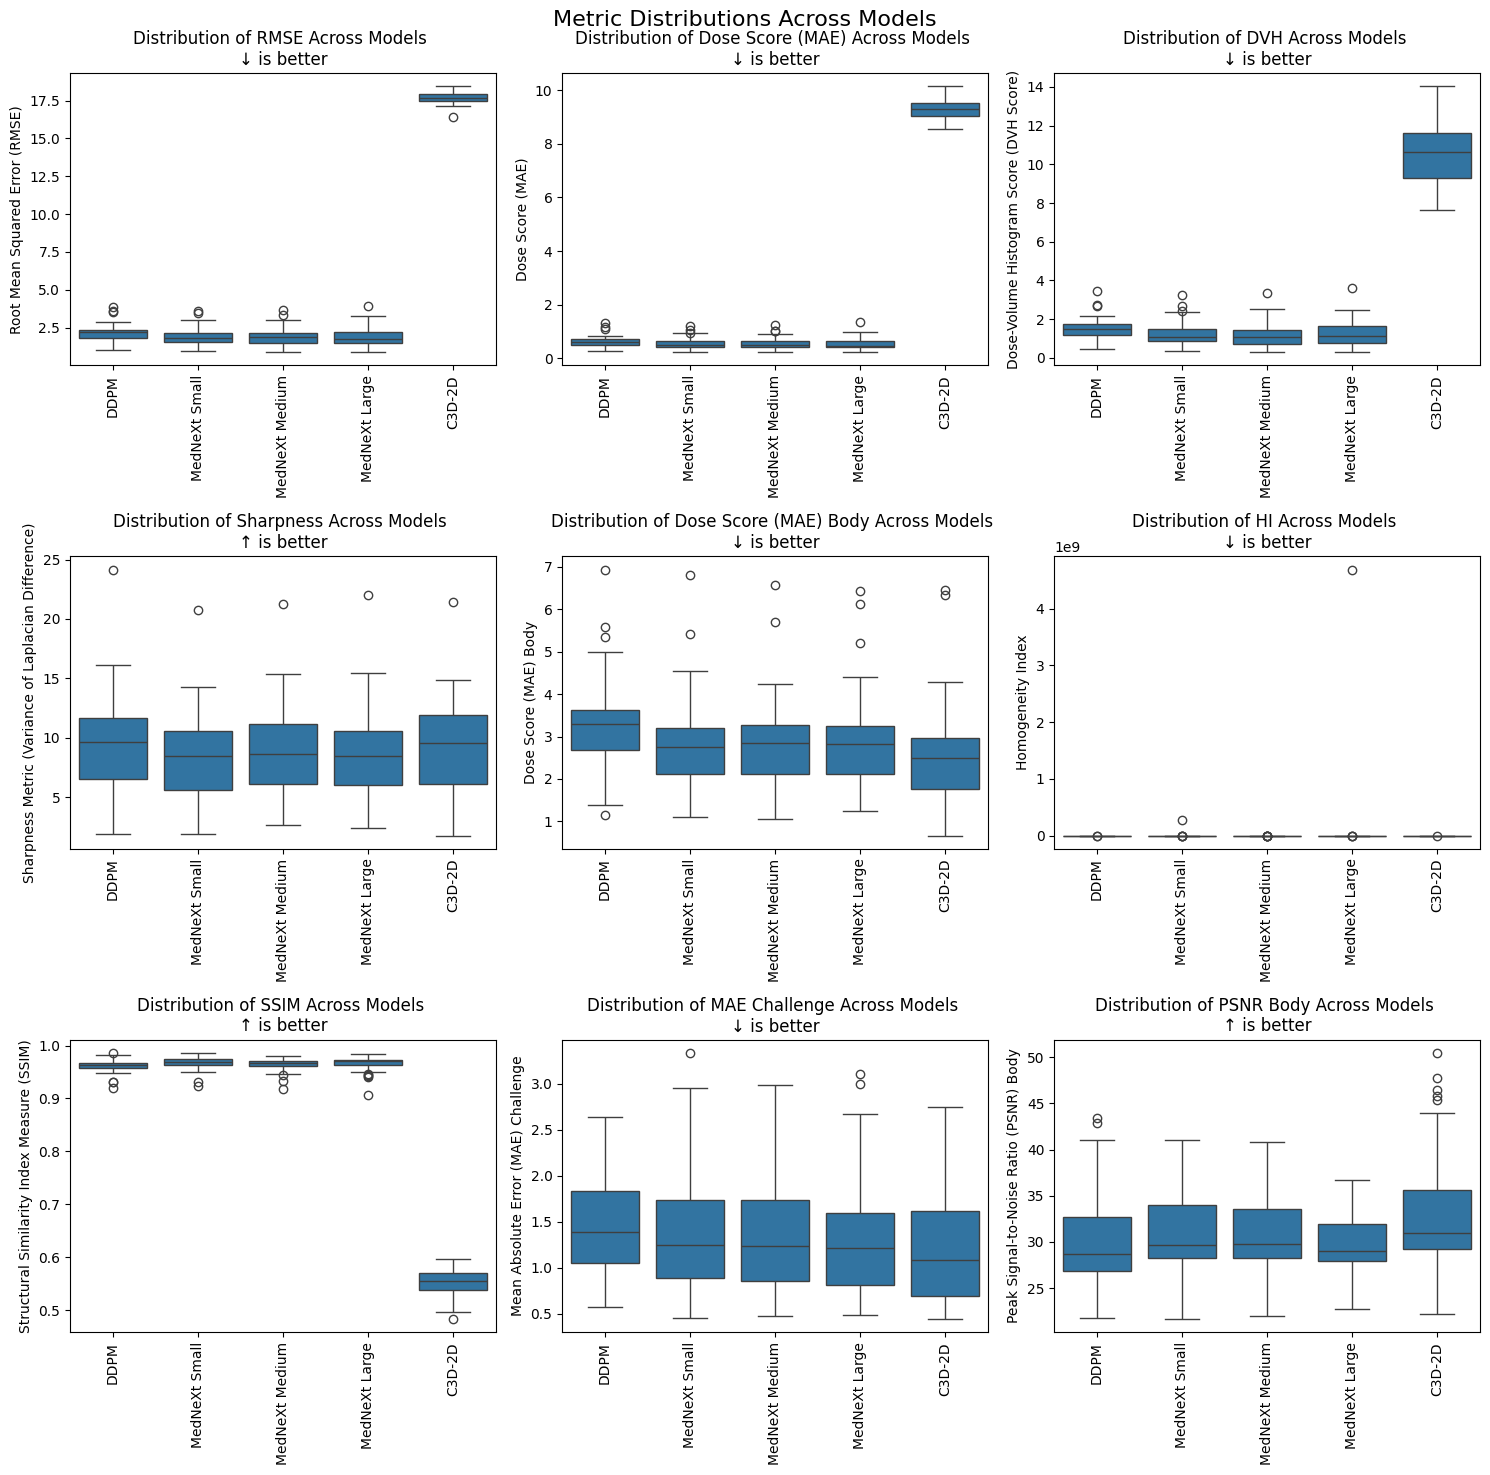

In [5]:
ax = comparison.plot_metric_distributions()

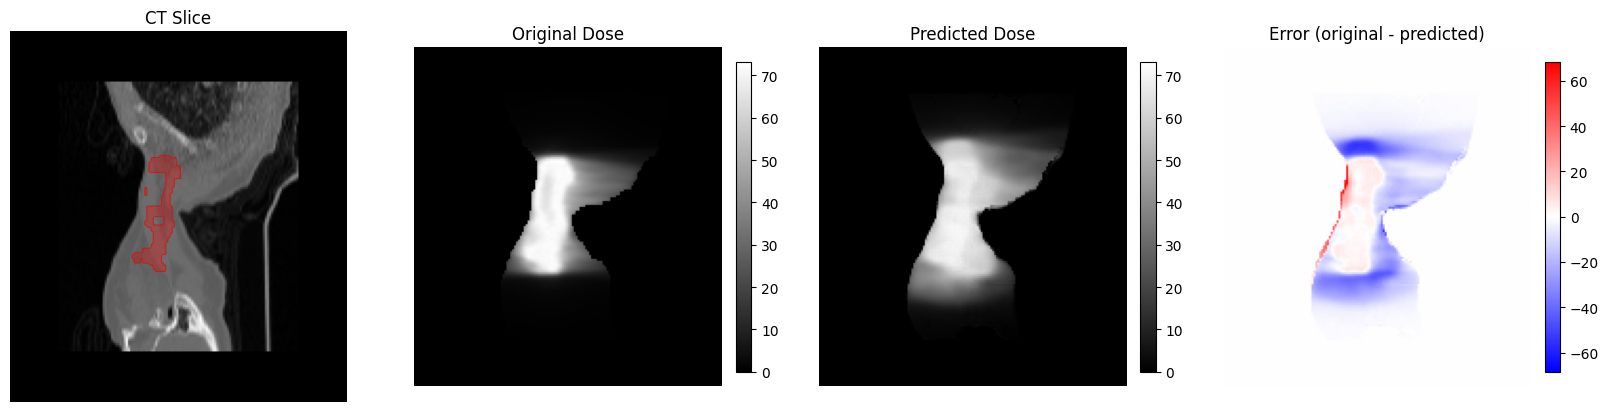

In [6]:
ax = mednext_m_results.for_sample('HN-CHUM-003+S2A4Ac+MOS_20285').visualise_slice(75)

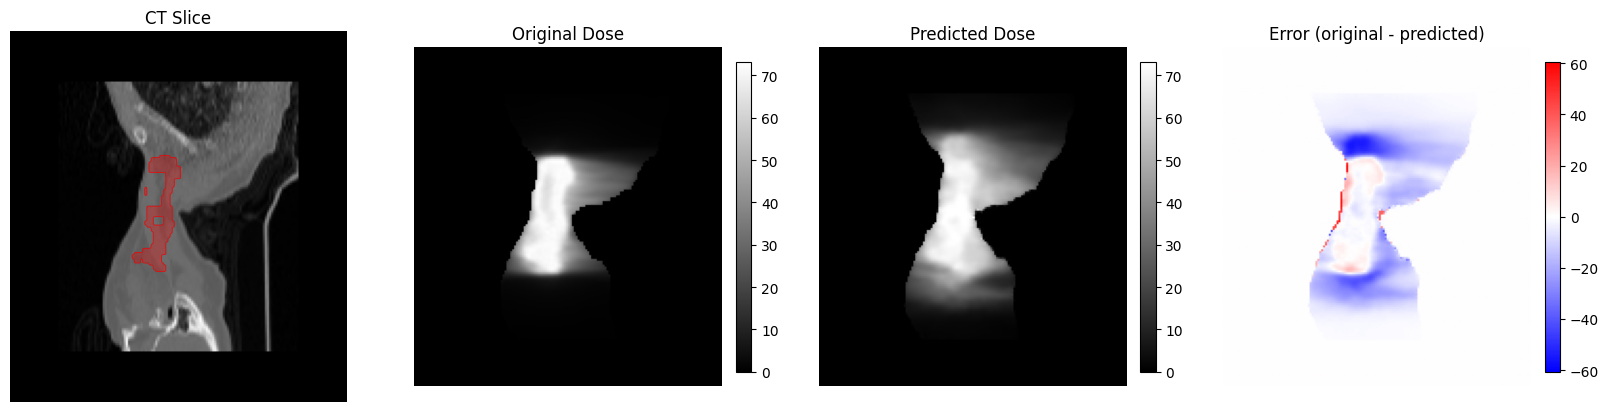

In [7]:
ax = ddpm_results.for_sample('HN-CHUM-003+S2A4Ac+MOS_20285').visualise_slice(75)

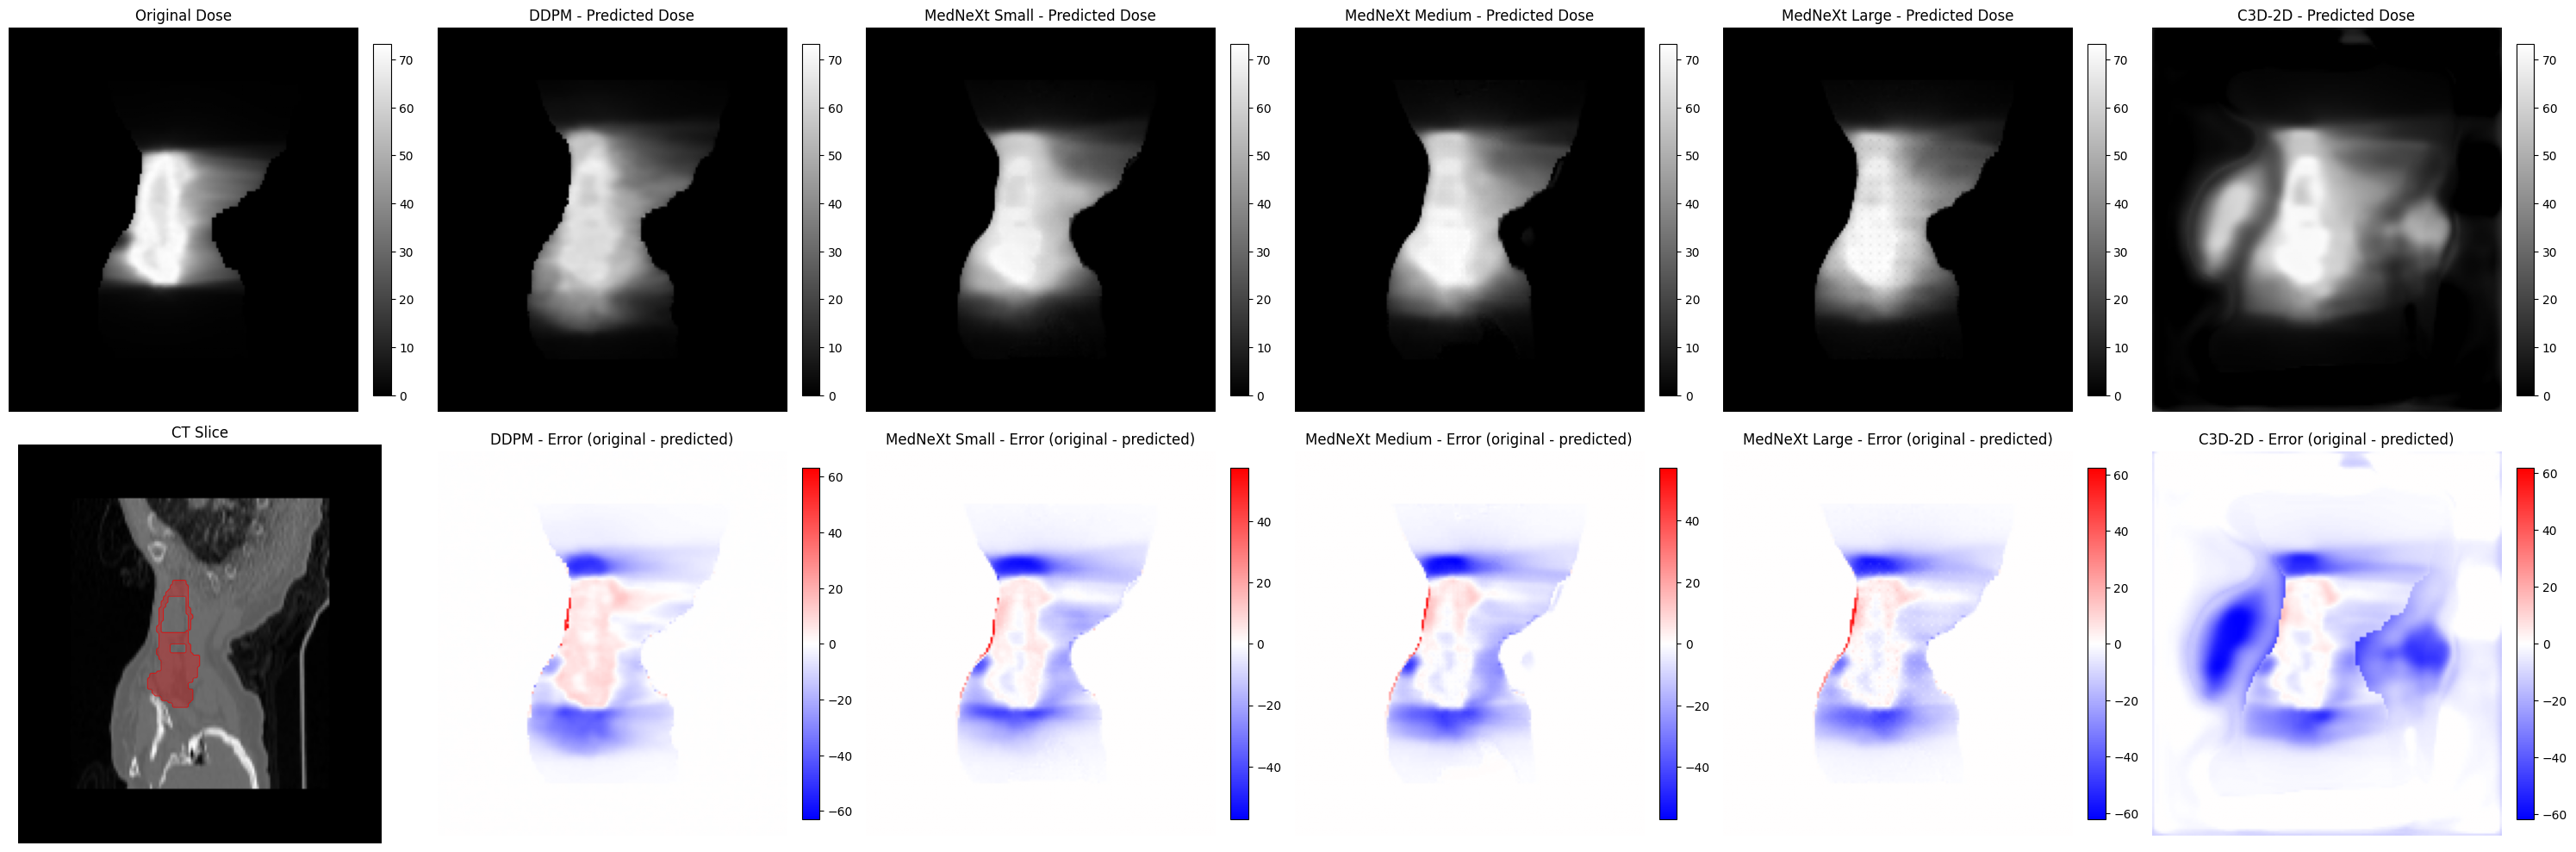

In [9]:
_ = comparison.viusalise_slice_comparison('HN-CHUM-003+S2A4Ac+MOS_20285', 80)

In [11]:
ax = mednext_m_results.plot_ptv_dvh()

: 

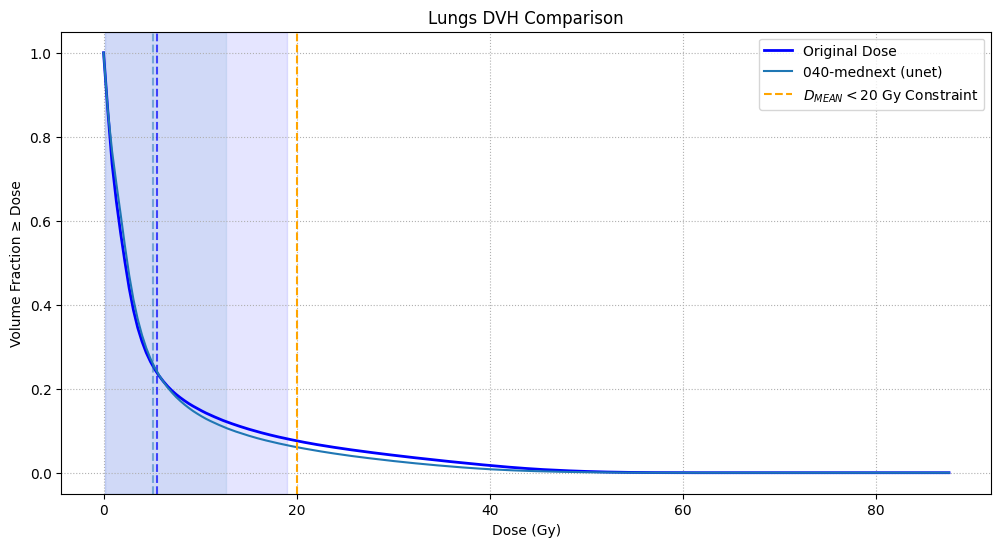

In [11]:
ax = mednext_results.plot_lungs_dvh()

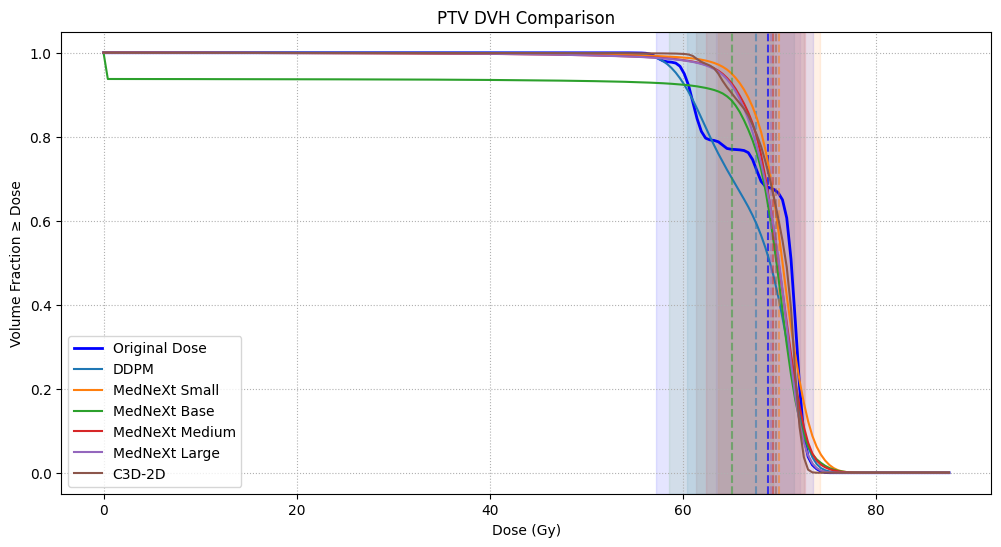

In [14]:
ax = comparison.plot_ptv_dvh()

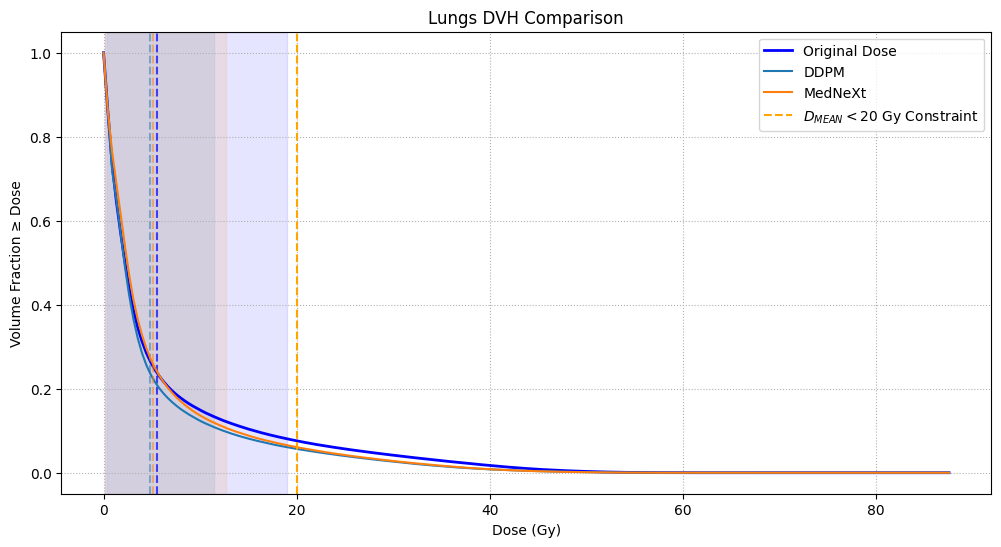

In [13]:
ax = comparison.plot_lungs_dvh()

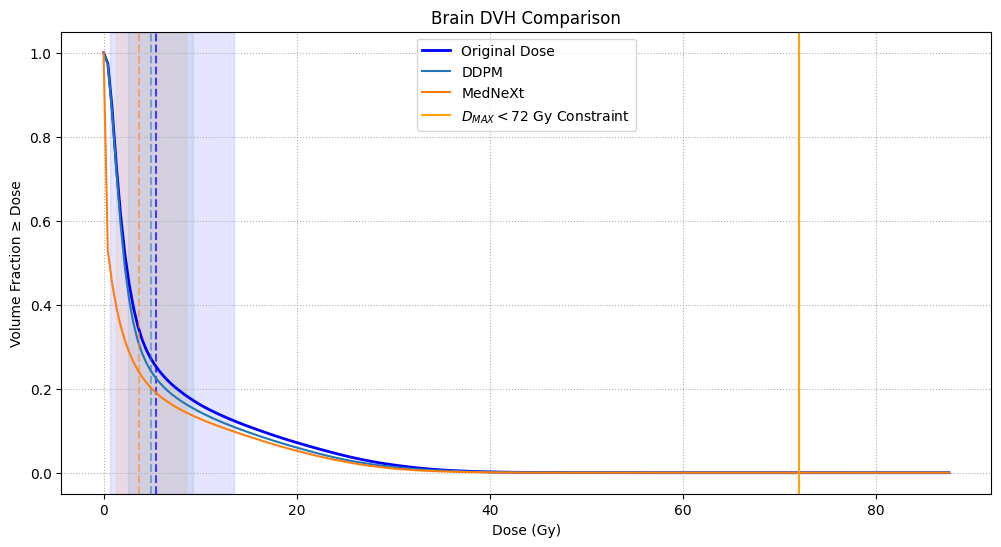

In [14]:
ax = comparison.plot_brain_dvh()

/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/.venv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)


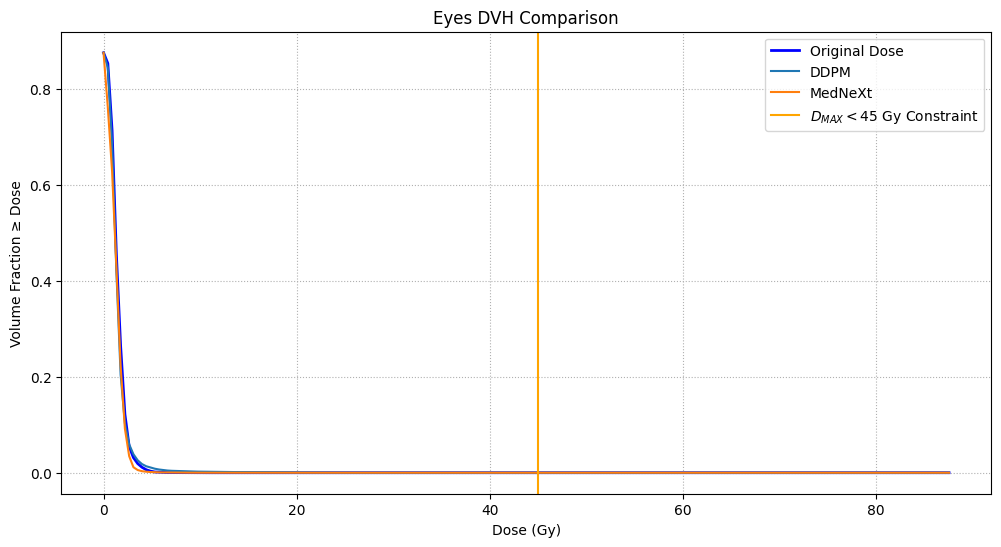

In [15]:
ax = comparison.plot_eye_dvh()

## C3D

In [7]:
c3d_2d_2_results = ModelResults('051-c3d-2d', 'unet', epoch=99, dataset_split='test', dataset=dataset)
c3d_2d_a0_results = ModelResults('052-c3d-2d-no-deep-supervision', 'unet', epoch=99, dataset_split='test', dataset=dataset)
c3d_2d_a1_results = ModelResults('053-c3d-2d-alpha-1', 'unet', epoch=99, dataset_split='test', dataset=dataset)

c3d_2d_comparison = ModelComparison(
    [
      ddpm_results,
      c3d_2d_results,
      c3d_2d_2_results,
      c3d_2d_a0_results,
      c3d_2d_a1_results,
    ],
    [
      'DDPM',
      'C3D-2D (a=0.5) v1',
      'C3D-2D (a=0.5) v2',
      'C3D-2D (a=0)',
      'C3D-2D (a=1)',
    ]
)

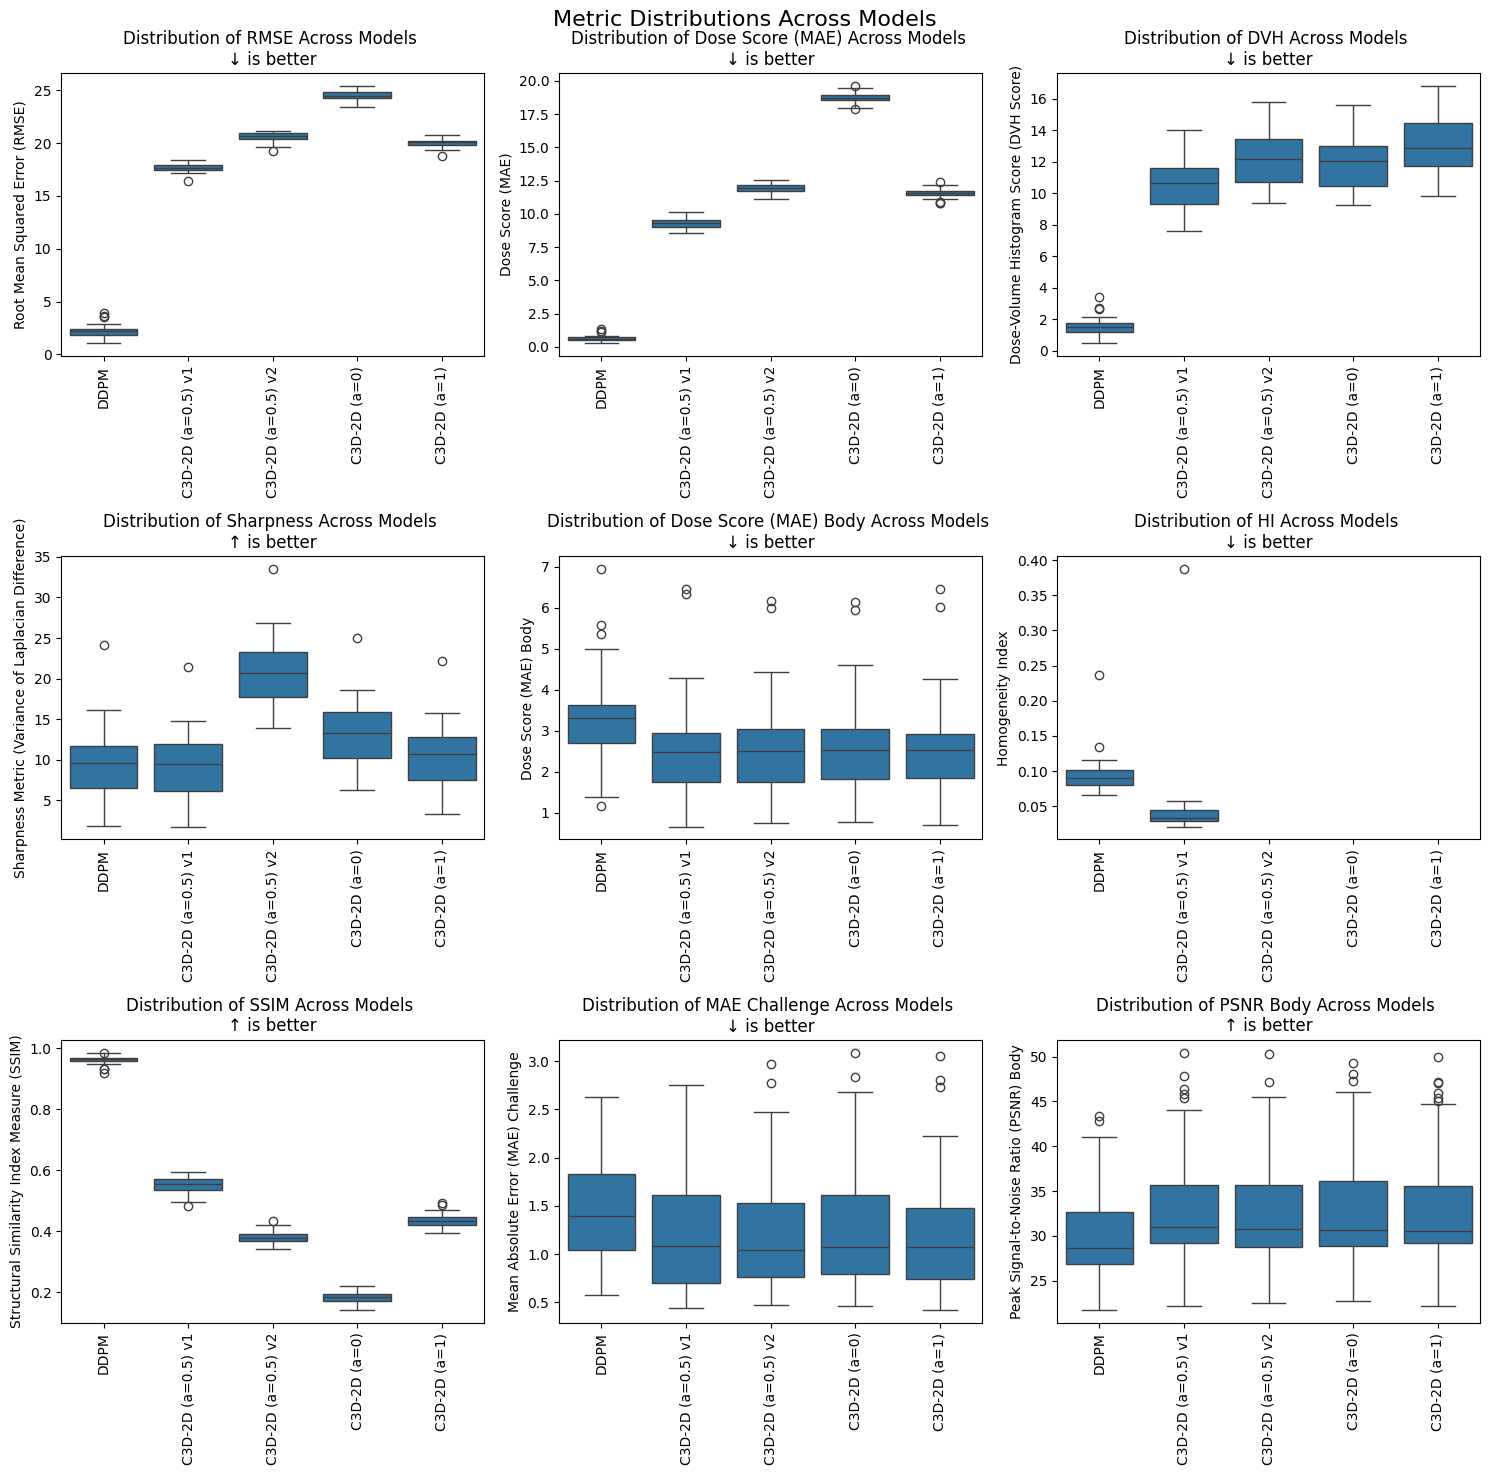

In [ ]:
_ = c3d_2d_comparison.plot_metric_distributions()

FileNotFoundError: [Errno 2] No such file or directory: '/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/samples/051-c3d-2d/unet/test_99/HN-CHUM-003+S2A4Ac+MOS_20285.npy'

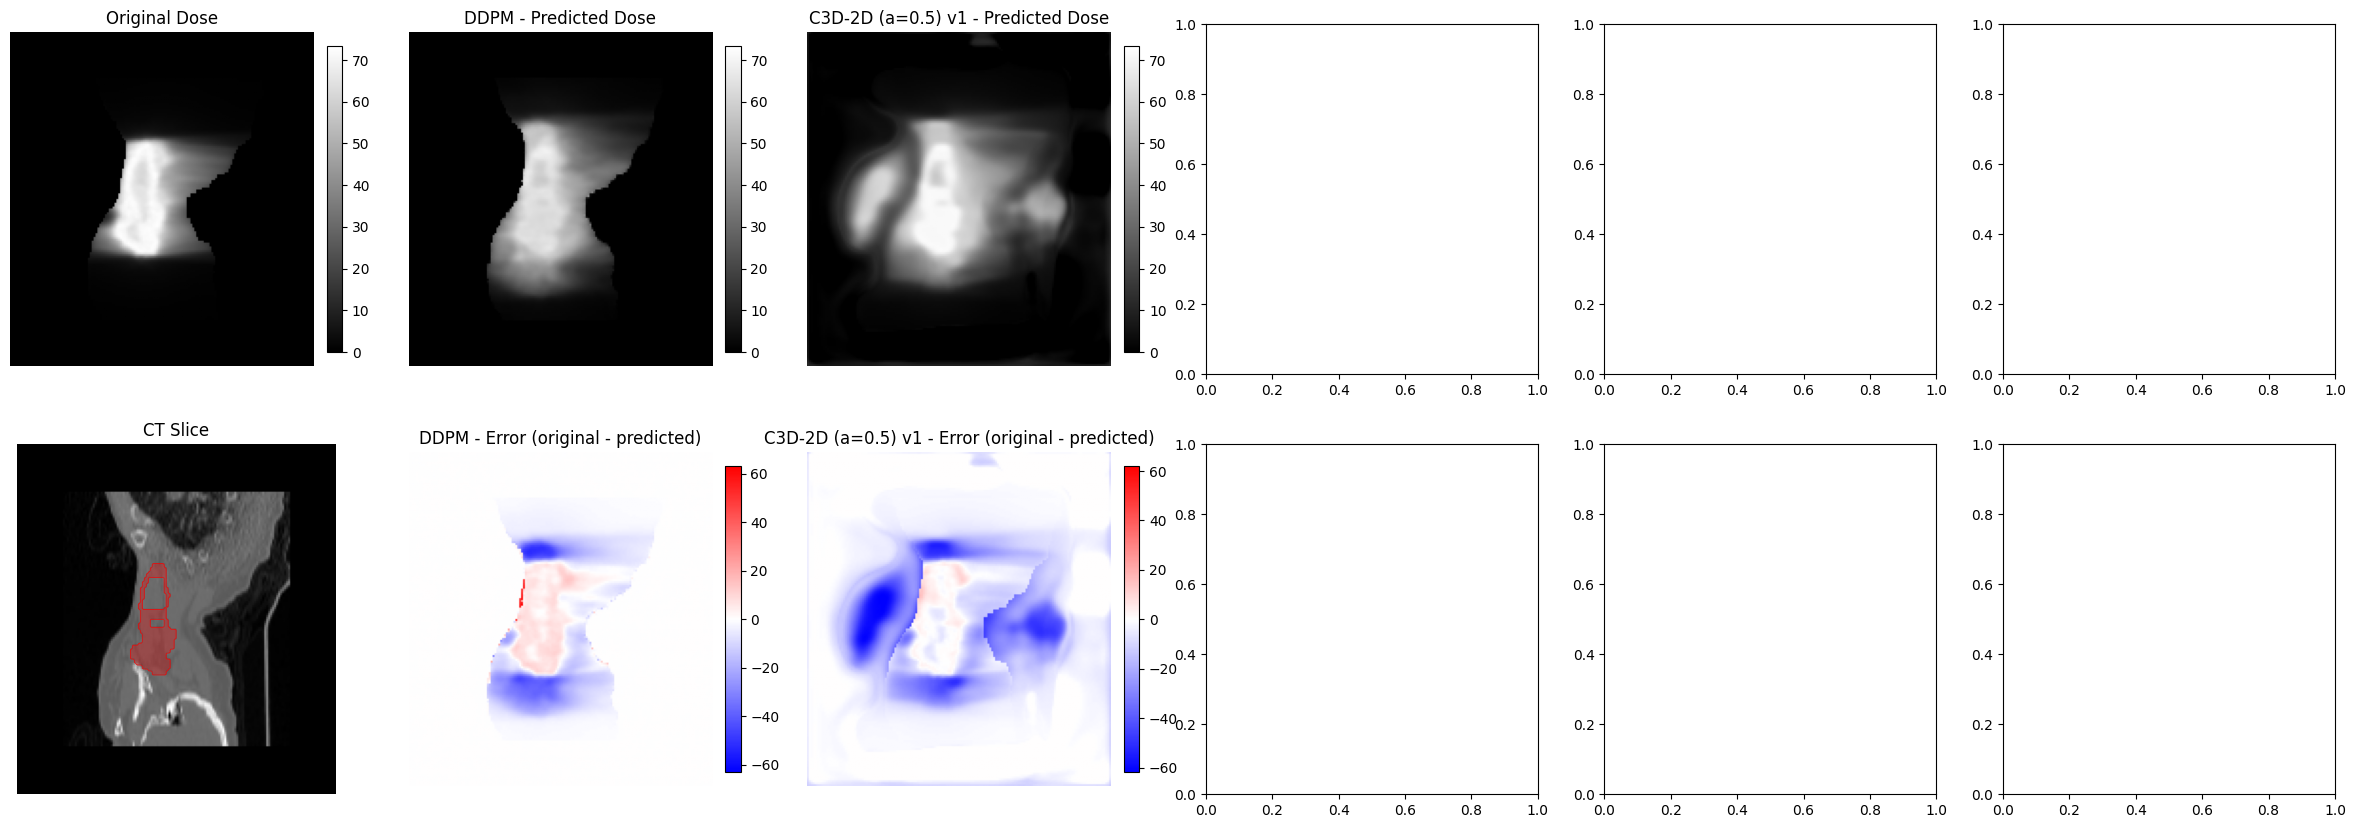

In [10]:
_ = c3d_2d_comparison.viusalise_slice_comparison('HN-CHUM-003+S2A4Ac+MOS_20285', 80)

## MedNeXt

In [13]:
mednext_m_v2_results = ModelResults('054-mednext-medium-v2', 'unet', epoch=99, dataset_split='test', dataset=dataset)
mednext_s_v2_results = ModelResults('055-mednext-small-v2', 'unet', epoch=99, dataset_split='test', dataset=dataset)
mednext_b_v2_results = ModelResults('056-mednext-base-v2', 'unet', epoch=99, dataset_split='test', dataset=dataset)
mednext_l_v2_results = ModelResults('057-mednext-large-v2', 'unet', epoch=99, dataset_split='test', dataset=dataset)

mednext_v2_comparison = ModelComparison(
    [
      ddpm_results,
      mednext_s_v2_results,
      mednext_b_v2_results,
      mednext_m_v2_results,
      mednext_l_v2_results,
    ],
    [
      'DDPM',
      'MedNeXt Small v2',
      'MedNeXt Base v2',
      'MedNeXt Medium v2',
      'MedNeXt Large v2',
    ]
)

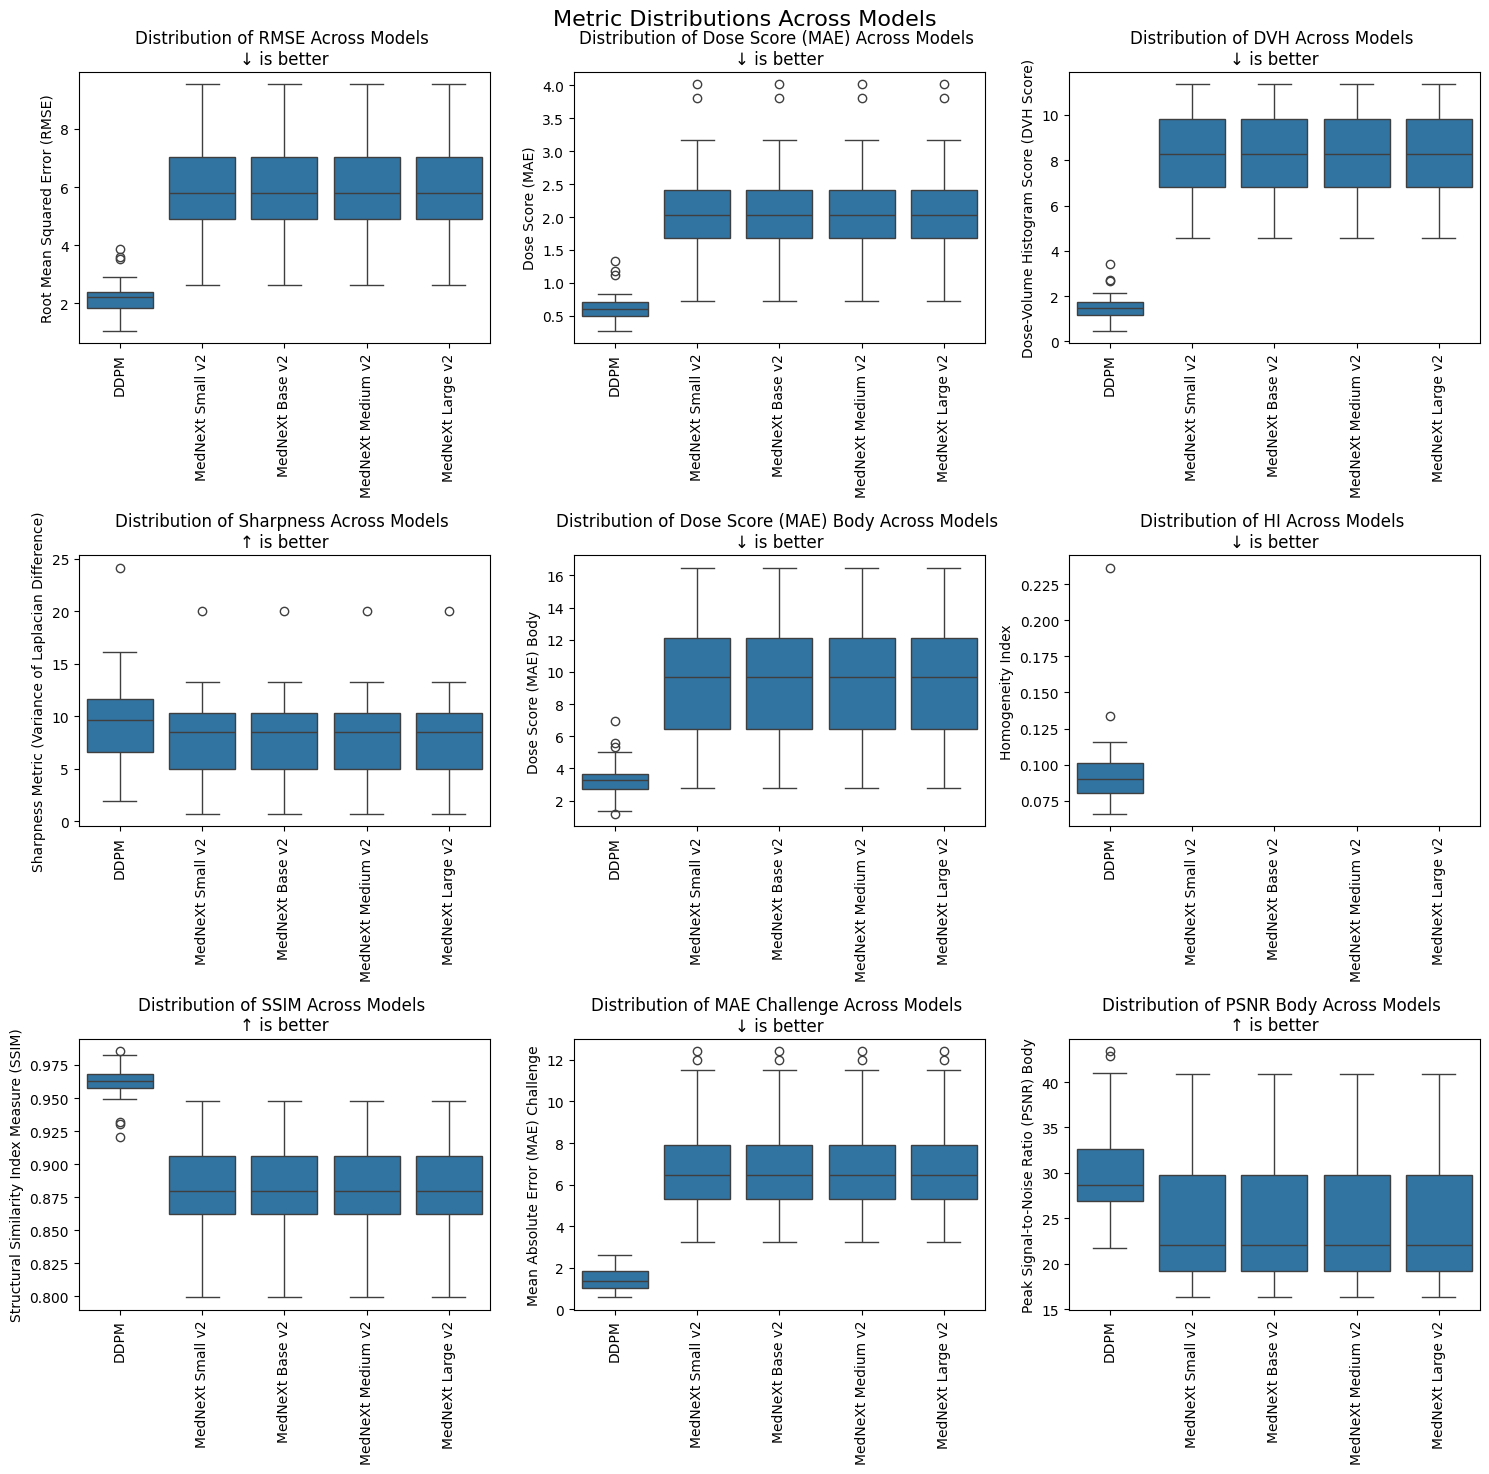

In [14]:
_ = mednext_v2_comparison.plot_metric_distributions()

Best model per metric:
                   metric     best_model direction
                      mse  MedNeXt Large         ↓
                     rmse  MedNeXt Large         ↓
                     psnr  MedNeXt Small         ↑
                     ssim  MedNeXt Small         ↑
                  ms_ssim  MedNeXt Large         ↑
                      dvh MedNeXt Medium         ↓
               dose_score  MedNeXt Large         ↓
        homogeneity_index         C3D-2D         ↓
                 mse_body         C3D-2D         ↓
                rmse_body         C3D-2D         ↓
                psnr_body         C3D-2D         ↑
          dose_score_body         C3D-2D         ↓
            mae_challenge         C3D-2D         ↓
       var_laplacian_pred         C3D-2D         ↓
     var_laplacian_target           DDPM         ↓
       var_laplacian_diff           DDPM         ↑
                  mse/PTV         C3D-2D         ↓
                 rmse/PTV         C3D-2D         ↓
        

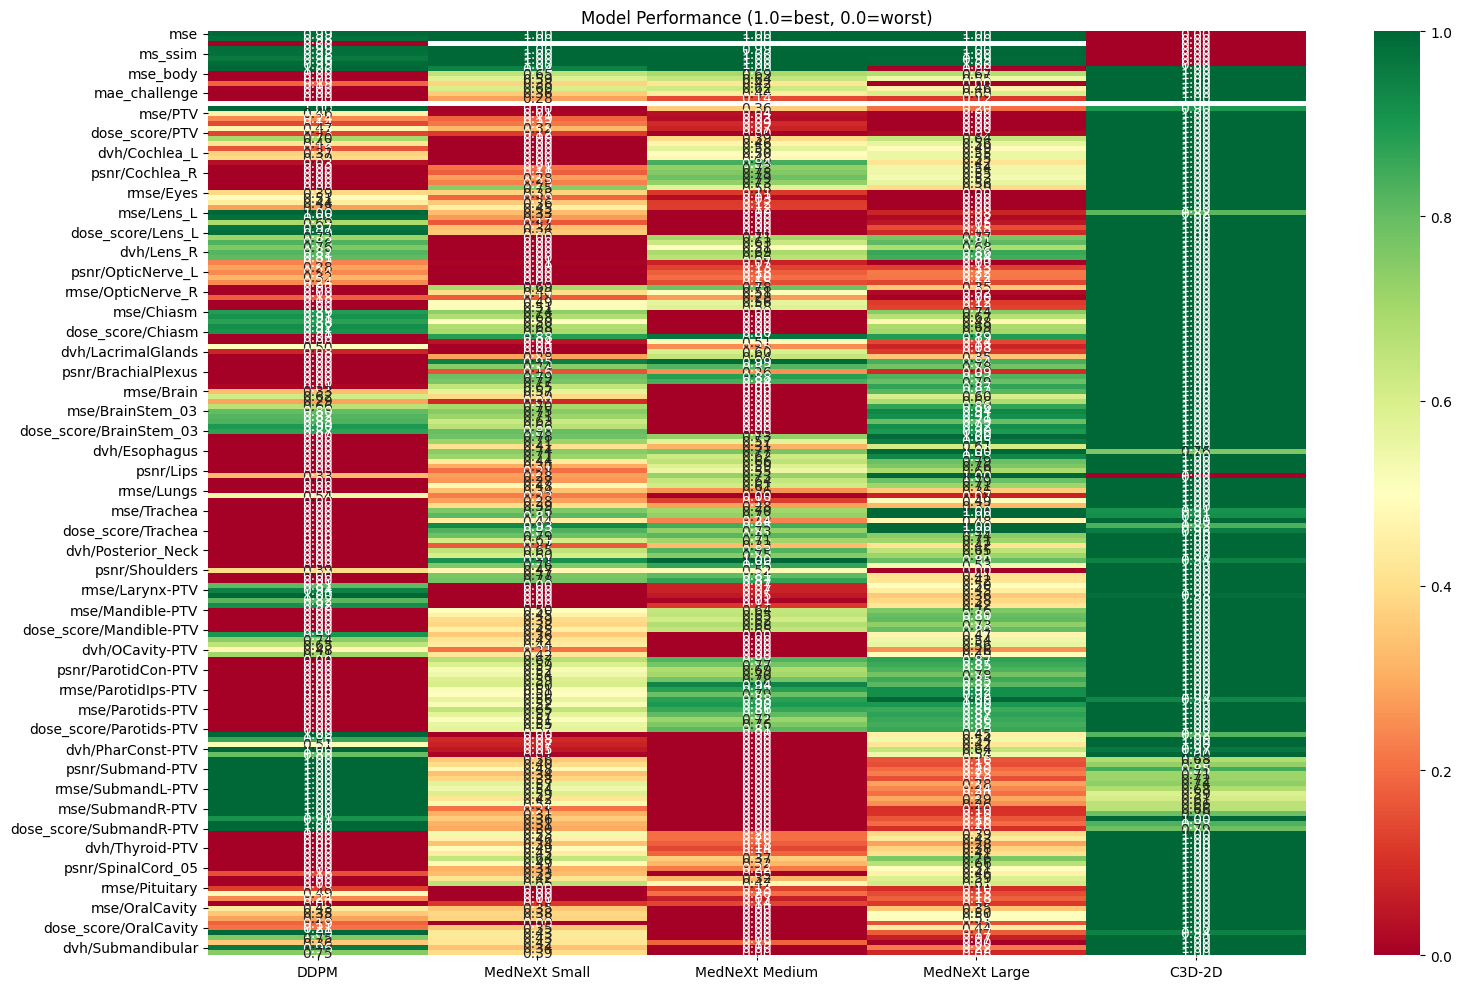

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from results import HIGHER_IS_BETTER

# Read metrics from all models
models = {
    'DDPM': ('024-baseline-1', 'ddpm-1000', 99),
    'MedNeXt Small': ('042-mednext-small', 'unet', 99),
    'MedNeXt Medium': ('040-mednext', 'unet', 99),
    'MedNeXt Large': ('044-mednext-large', 'unet', 99),
    'C3D-2D': ('041-c3d-2d', 'unet', 99),
}

metrics = {}
for name, (model, sampling, epoch) in models.items():
    path = Path(f'../samples/{model}/{sampling}/test_{epoch}/_overall_metrics.csv')
    if path.exists():
        metrics[name] = pd.read_csv(path).iloc[0]

df = pd.DataFrame(metrics).T

# Get all metric columns (exclude duration and slice_index)
all_metrics = [col for col in df.columns if col not in ['duration', 'slice_index']]

# Find best model for each metric
best = []
for col in all_metrics:
    # Strip region suffix (e.g., "mse/PTV" -> "mse")
    base_metric = col.split('/')[0]
    is_higher_better = base_metric in HIGHER_IS_BETTER
    best_model = df[col].idxmax() if is_higher_better else df[col].idxmin()
    best.append({'metric': col, 'best_model': best_model, 'direction': '↑' if is_higher_better else '↓'})

best_df = pd.DataFrame(best)
print("Best model per metric:")
print(best_df.to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(16, 10))
normalized = df[all_metrics].copy()
for col in all_metrics:
    vals = df[col]
    base_metric = col.split('/')[0]
    if base_metric in HIGHER_IS_BETTER:
        normalized[col] = (vals - vals.min()) / (vals.max() - vals.min())
    else:
        normalized[col] = (vals.max() - vals) / (vals.max() - vals.min())

sns.heatmap(normalized.T, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1, ax=ax)
ax.set_title('Model Performance (1.0=best, 0.0=worst)')
plt.tight_layout()